# DSC 411/511 Project
# Notebook 08: RQ6 (new): Do Lower-Income Neighbourhoods Get Paid Less, After We Account for the Flood?

**Class topics:** Lecture 07 (logistic regression and reading coefficients, odds), Lecture 03 (discretization into
quintiles, aggregation), Lecture 04 (confounding features), plus regression with controls as an extension.

---

**How this question was derived.** In notebook 02 the ACS columns (income, % owners, % non-Hispanic White) had high
mutual information with both outcomes. That can mean two very different things:
1. **Exposure**: poorer and richer neighbourhoods sit in different places, and floods hit places unequally; or
2. **Treatment**: similar claims are settled differently depending on the neighbourhood.

Published work points to (2), at least in part:
- The **Urban Institute** study *Housing Resilience in Greater New Orleans* (2008-2018) found **no differences by
  race/ethnicity or income in the cost and coverage of equivalent policies**, but did find **"apparent differences in
  claims treatment"**.
- *Are Underserved Populations Left Out of National Flood Mitigation Efforts...?* (J. Climate Resilience and Justice,
  2023) found that majority non-White tracts in majority-White counties receive **disproportionately fewer NFIP
  claims** per person.

Both are descriptive: they do not control for how hard each claim was hit. The combined dataset lets us repeat the raw
comparison and then add controls for building, policy, storm and damage.

> **RQ6. Do claims in lower-income (and majority non-White) neighbourhoods have higher non-payment rates and lower
> payment-to-damage ratios, and does the gap remain after controlling for building, policy, storm exposure and damage?**

**Caution (ecological inference).** ACS values describe the **block group**, not the policyholder. We can talk about
neighbourhoods, not about individual households.

---
# Section 0: Setup

In [1]:
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

sys.path.append('/Users/home/workspace/School/DataMining/nfip_claims')
from nfip_project_utils import *

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.width', 180)

claims = load_clean_claims()
claims = claims[claims['acs_join_level'] != 'none'].copy()
print(f'Claims with an ACS match: {len(claims):,}')

Claims with an ACS match: 250,926


---
# Section 1: Building the Neighbourhood Groups (discretization, Lecture 03)

Income is split into **quintiles** using the claim population, so each group has about 20% of claims.
Race is a simple, published-style split: majority non-Hispanic White (> 50%) or not.

In [2]:
claims['income_quintile'] = pd.qcut(claims['acs_median_household_income'], 5, labels=['Q1_lowest', 'Q2', 'Q3', 'Q4', 'Q5_highest'])
claims['majority_white'] = np.where(claims['acs_pct_non_hispanic_white'] > 50, 'majority_NH_white', 'majority_non_white')
quintile_edges = claims.groupby('income_quintile')['acs_median_household_income'].agg(['min', 'max']).round(0)
print('Income quintile edges (block-group median household income, $):')
print(quintile_edges.to_string())
print('\nClaims by race group:', claims['majority_white'].value_counts().to_dict())

# Payment-to-damage ratio: only where there was damage. Clipped at 1.5 because payments can include items not in
# buildingDamageAmount (notebook 01, Section 5.2).
damaged = claims[claims['buildingDamageAmount'] > 0].copy()
damaged['payment_to_damage_ratio'] = (damaged['amountPaidOnBuildingClaim'] / damaged['buildingDamageAmount']).clip(0, 1.5)
claims['not_paid'] = 1 - claims['building_paid_flag']

Income quintile edges (block-group median household income, $):
                      min       max
income_quintile                    
Q1_lowest          2499.0   58083.0
Q2                58087.0   73917.0
Q3                73920.0   92266.0
Q4                92273.0  124125.0
Q5_highest       124127.0  250001.0

Claims by race group: {'majority_NH_white': 202174, 'majority_non_white': 48752}


---
# Section 2: Reproducing the Raw (Unadjusted) Comparison

In [3]:
raw_by_income = claims.groupby('income_quintile').agg(claims=('id', 'size'), not_paid_rate=('not_paid', 'mean'),
                                                      median_paid_if_paid=('amountPaidOnBuildingClaim', lambda s: s[s > 0].median()),
                                                      median_damage=('buildingDamageAmount', 'median'),
                                                      median_rain_3day=('rain_3day_mm', 'median'),
                                                      share_inside_SFHA=('in_special_flood_hazard_area', 'mean'),
                                                      median_coverage=('totalBuildingInsuranceCoverage', 'median'))
raw_by_income['median_payment_to_damage'] = damaged.groupby('income_quintile')['payment_to_damage_ratio'].median()
raw_by_race = claims.groupby('majority_white').agg(claims=('id', 'size'), not_paid_rate=('not_paid', 'mean'),
                                                   median_paid_if_paid=('amountPaidOnBuildingClaim', lambda s: s[s > 0].median()),
                                                   median_damage=('buildingDamageAmount', 'median'),
                                                   median_rain_3day=('rain_3day_mm', 'median'),
                                                   share_inside_SFHA=('in_special_flood_hazard_area', 'mean'),
                                                   median_coverage=('totalBuildingInsuranceCoverage', 'median'))
raw_by_race['median_payment_to_damage'] = damaged.groupby('majority_white')['payment_to_damage_ratio'].median()
print('By income quintile:')
print(raw_by_income.round(3).to_string())
print('\nBy race group:')
print(raw_by_race.round(3).to_string())
raw_by_income.round(4).to_csv(TABLE_DIR / '08_rq6_raw_by_income.csv')
raw_by_race.round(4).to_csv(TABLE_DIR / '08_rq6_raw_by_race.csv')

By income quintile:
                 claims  not_paid_rate  median_paid_if_paid  median_damage  median_rain_3day  share_inside_SFHA  median_coverage  median_payment_to_damage
income_quintile                                                                                                                                           
Q1_lowest         50189          0.176            34007.375        26360.0           133.990              0.757         220000.0                     0.940
Q2                50204          0.178            40678.980        29362.0           142.494              0.818         250000.0                     0.945
Q3                50279          0.168            47483.000        33273.0           138.462              0.830         250000.0                     0.953
Q4                50287          0.168            43038.960        31360.0           105.257              0.836         250000.0                     0.950
Q5_highest        49967          0.146            

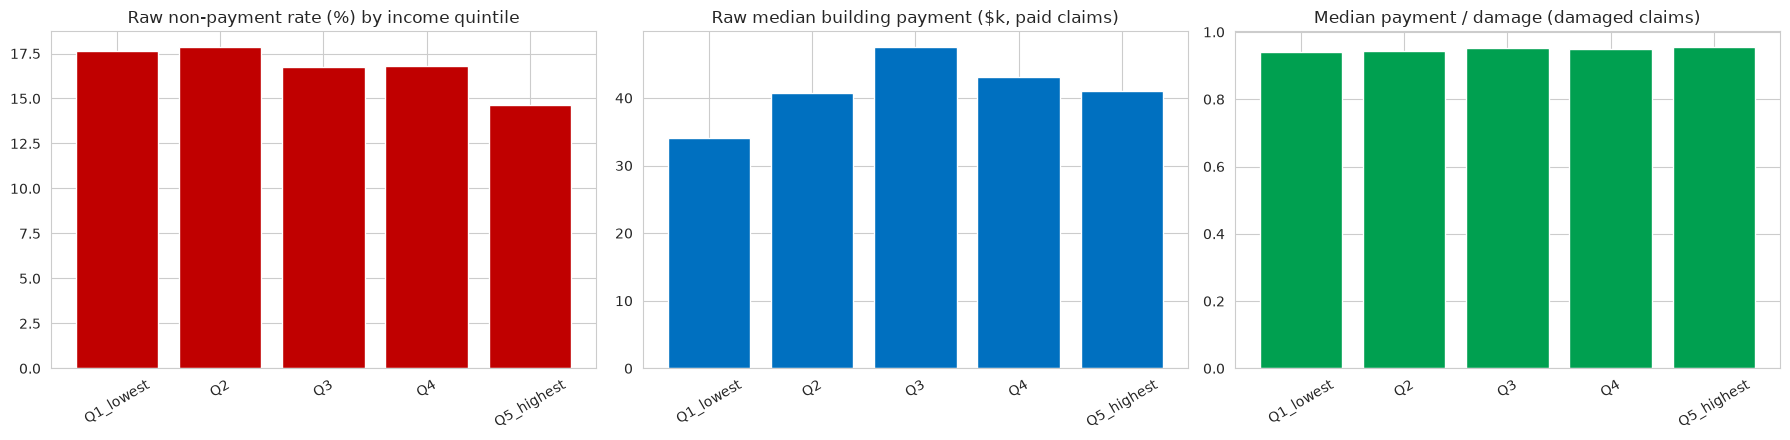

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].bar(raw_by_income.index.astype(str), raw_by_income['not_paid_rate'] * 100, color='#C00000')
axes[0].set_title('Raw non-payment rate (%) by income quintile')
axes[1].bar(raw_by_income.index.astype(str), raw_by_income['median_paid_if_paid'] / 1000, color='#0070C0')
axes[1].set_title('Raw median building payment ($k, paid claims)')
axes[2].bar(raw_by_income.index.astype(str), raw_by_income['median_payment_to_damage'], color='#00A050')
axes[2].set_title('Median payment / damage (damaged claims)')
for ax in axes:
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig(FIGURE_DIR / '08_raw_by_income.png', dpi=120)
plt.show()

**Reading the raw numbers.**
- **Income.** Claims in the lowest-income quintile (block-group income below about $58k) were not paid 17.6% of the
  time, against 14.6% in the highest quintile. Their median payment was $34k against $41k.
- **Race.** Claims in majority non-White block groups were not paid 21.1% of the time, against 15.7%. Their median
  payment was $30k against $44k.
- **But the groups were not hit in the same way.** Majority non-White areas had much more rain (median 3-day rain
  176 mm vs 111 mm), fewer claims inside the SFHA (67% vs 85%) and lower damage ($22k vs $33k). The lowest
  income quintile has lower coverage ($220k vs $250k) and fewer SFHA claims. Lower payments partly follow lower
  damage and lower coverage. A raw gap mixes treatment with exposure, so we need controls.

---
# Section 3: Logistic Regression with Controls (Lecture 07, Sections 1-2)

For non-payment we fit four nested logistic models. Each adds one block of controls. The coefficient of each income
quintile, turned into an **odds ratio** (OR = e^coefficient), compares that quintile with the **highest** quintile.
OR = 1 means no difference; OR > 1 means higher odds of not being paid.

| Model | Controls |
|---|---|
| M1 | none (raw gap) |
| M2 | + building and policy: flood zone, occupancy, foundation, coverage, deductible, age, primary residence, RR2.0 |
| M3 | + flood exposure: PRISM rain, storm distance and wind, coast distance, **state and loss year** |
| M4 | + **adjuster damage** (log). Not allowed in a *prediction* model (it leaks), but in a *fairness* question it is the right control: we ask whether claims with the **same damage** are paid differently |

Standard errors are **clustered by county**, because claims in the same county share a storm and a local adjusting
team, so they are not independent.

In [5]:
claims['log_coverage'] = claims['log_building_coverage']
claims['log_deductible'] = np.log10(claims['building_deductible_usd'])
claims['log_rain_3day'] = np.log1p(claims['rain_3day_mm'])
claims['log_storm_distance'] = np.log1p(claims['storm_distance_km'])
claims['log_coast_distance'] = np.log1p(claims['coast_distance_km'])
claims['log_damage'] = np.log1p(claims['buildingDamageAmount'])
claims['loss_year_text'] = claims['loss_year'].astype(str)

BUILDING_POLICY = ('C(flood_zone_group) + C(occupancy_group) + C(foundation_group) + log_coverage + log_deductible'
                   ' + building_age_at_loss + primaryResidenceIndicator + rated_by_risk_rating_2')
EXPOSURE = 'log_rain_3day + log_storm_distance + storm_wind_proxy_at_claim_kt + log_coast_distance + C(state) + C(loss_year_text)'
SPECIFICATIONS = {
    'M1 raw': '',
    'M2 + building/policy': BUILDING_POLICY,
    'M3 + flood exposure, state, year': BUILDING_POLICY + ' + ' + EXPOSURE,
    'M4 + adjuster damage': BUILDING_POLICY + ' + ' + EXPOSURE + ' + log_damage',
}
model_data = claims.dropna(subset=['log_damage']).copy()
model_data = model_data[model_data['state'].map(model_data['state'].value_counts()) >= 200]
print(f'Rows used in all models (damage recorded, states with >= 200 claims): {len(model_data):,}')


def income_effects(result, specification, kind):
    rows = []
    for quintile in ['Q1_lowest', 'Q2', 'Q3', 'Q4']:
        term = f"C(income_quintile, Treatment('Q5_highest'))[T.{quintile}]"
        coefficient, standard_error = result.params[term], result.bse[term]
        low, high = coefficient - 1.96 * standard_error, coefficient + 1.96 * standard_error
        if kind == 'logit':
            coefficient, low, high = np.exp(coefficient), np.exp(low), np.exp(high)
        rows.append({'model': specification, 'quintile': quintile, 'estimate': coefficient, 'ci_low': low, 'ci_high': high,
                     'p_value': result.pvalues[term]})
    return rows


logit_rows = []
for specification, controls in SPECIFICATIONS.items():
    formula = "not_paid ~ C(income_quintile, Treatment('Q5_highest'))" + (f' + {controls}' if controls else '')
    result = smf.logit(formula, data=model_data).fit(disp=False, maxiter=200, cov_type='cluster',
                                                     cov_kwds={'groups': pd.factorize(model_data['county_geoid'])[0]})
    logit_rows += income_effects(result, specification, 'logit')
    print(f'{specification:<36} pseudo R2 = {result.prsquared:.3f}')
logit_table = pd.DataFrame(logit_rows)
logit_table.round(4).to_csv(TABLE_DIR / '08_rq6_nonpayment_odds_ratios.csv', index=False)
print('\nOdds ratio of NOT being paid, each quintile vs the highest-income quintile:')
print(logit_table.pivot(index='quintile', columns='model', values='estimate').round(3).to_string())

Rows used in all models (damage recorded, states with >= 200 claims): 232,168


M1 raw                               pseudo R2 = 0.002


M2 + building/policy                 pseudo R2 = 0.066


M3 + flood exposure, state, year     pseudo R2 = 0.088


M4 + adjuster damage                 pseudo R2 = 0.560

Odds ratio of NOT being paid, each quintile vs the highest-income quintile:
model      M1 raw  M2 + building/policy  M3 + flood exposure, state, year  M4 + adjuster damage
quintile                                                                                       
Q1_lowest   1.358                 1.319                             1.283                 1.252
Q2          1.336                 1.254                             1.219                 1.219
Q3          1.238                 1.182                             1.164                 1.176
Q4          1.203                 1.161                             1.147                 1.134


---
# Section 4: Payment-to-Damage Ratio with Controls (linear regression)

Among claims with damage, we model the payment-to-damage ratio. The coefficient of a quintile is the difference in the
ratio (in percentage points after multiplying by 100) compared with the highest quintile, holding the controls fixed.

In [6]:
damaged = damaged.merge(claims[['id', 'log_coverage', 'log_deductible', 'log_rain_3day', 'log_storm_distance', 'log_coast_distance',
                                'log_damage', 'loss_year_text']], on='id', how='left')
damaged = damaged[damaged['state'].map(damaged['state'].value_counts()) >= 200]
ols_rows = []
for specification, controls in SPECIFICATIONS.items():
    formula = "payment_to_damage_ratio ~ C(income_quintile, Treatment('Q5_highest'))" + (f' + {controls}' if controls else '')
    result = smf.ols(formula, data=damaged).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(damaged['county_geoid'])[0]})
    ols_rows += income_effects(result, specification, 'ols')
    print(f'{specification:<36} R2 = {result.rsquared:.3f}')
ols_table = pd.DataFrame(ols_rows)
ols_table.round(4).to_csv(TABLE_DIR / '08_rq6_payment_ratio_effects.csv', index=False)
print('\nDifference in payment/damage ratio, each quintile vs the highest quintile:')
print(ols_table.pivot(index='quintile', columns='model', values='estimate').round(4).to_string())

M1 raw                               R2 = 0.001


M2 + building/policy                 R2 = 0.128


M3 + flood exposure, state, year     R2 = 0.147


M4 + adjuster damage                 R2 = 0.231

Difference in payment/damage ratio, each quintile vs the highest quintile:
model      M1 raw  M2 + building/policy  M3 + flood exposure, state, year  M4 + adjuster damage
quintile                                                                                       
Q1_lowest -0.0274               -0.0222                           -0.0228               -0.0143
Q2        -0.0212               -0.0135                           -0.0189               -0.0117
Q3        -0.0136               -0.0120                           -0.0138               -0.0100
Q4        -0.0165               -0.0162                           -0.0128               -0.0083


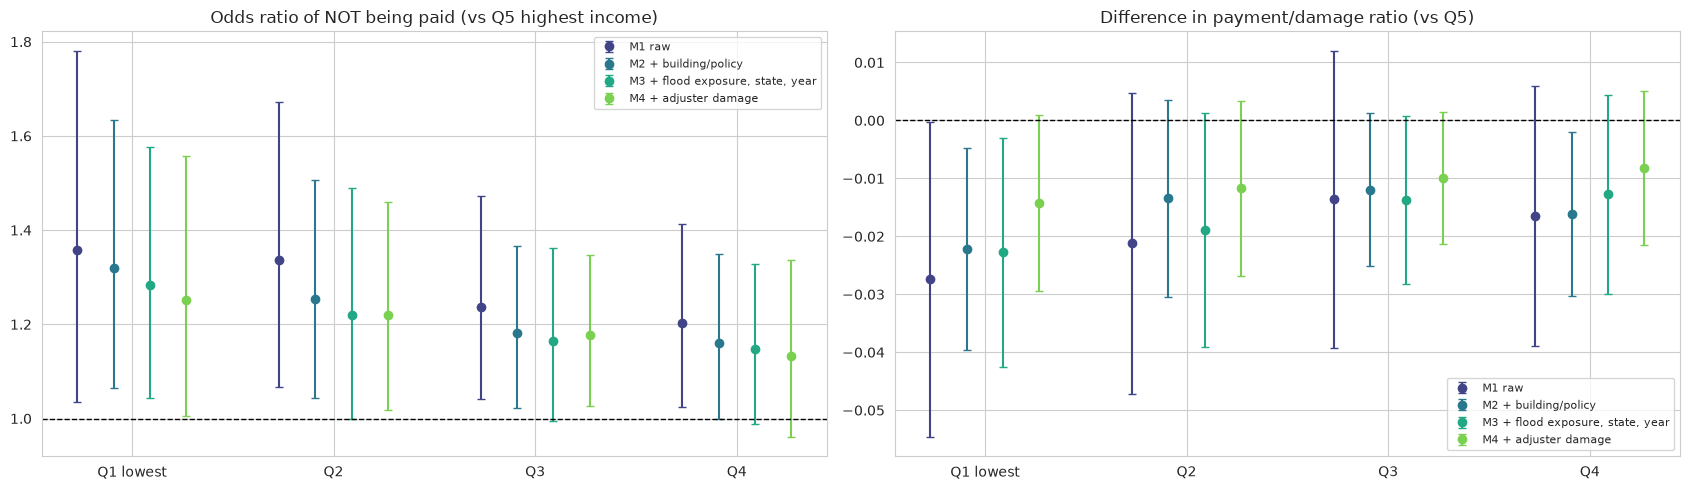

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
model_order = list(SPECIFICATIONS)
colors = sns.color_palette('viridis', len(model_order))
for ax, table, title, reference in [(axes[0], logit_table, 'Odds ratio of NOT being paid (vs Q5 highest income)', 1.0),
                                    (axes[1], ols_table, 'Difference in payment/damage ratio (vs Q5)', 0.0)]:
    for model_index, model_name in enumerate(model_order):
        subset = table[table['model'] == model_name].reset_index(drop=True)
        positions = np.arange(len(subset)) + (model_index - 1.5) * 0.18
        ax.errorbar(positions, subset['estimate'], yerr=[subset['estimate'] - subset['ci_low'], subset['ci_high'] - subset['estimate']],
                    fmt='o', color=colors[model_index], label=model_name, capsize=3)
    ax.axhline(reference, color='k', ls='--', lw=1)
    ax.set_xticks(range(4))
    ax.set_xticklabels(['Q1 lowest', 'Q2', 'Q3', 'Q4'])
    ax.set_title(title)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURE_DIR / '08_rq6_effects_by_model.png', dpi=120)
plt.show()

---
# Section 5: The Same Question for Race (majority non-Hispanic White vs not)

In [8]:
race_rows = []
for specification in ['M1 raw', 'M3 + flood exposure, state, year', 'M4 + adjuster damage']:
    controls = SPECIFICATIONS[specification]
    formula = "not_paid ~ C(majority_white, Treatment('majority_NH_white'))" + (f' + {controls}' if controls else '')
    result = smf.logit(formula, data=model_data).fit(disp=False, maxiter=200, cov_type='cluster',
                                                     cov_kwds={'groups': pd.factorize(model_data['county_geoid'])[0]})
    term = "C(majority_white, Treatment('majority_NH_white'))[T.majority_non_white]"
    ols_result = smf.ols(formula.replace('not_paid', 'payment_to_damage_ratio'), data=damaged).fit(
        cov_type='cluster', cov_kwds={'groups': pd.factorize(damaged['county_geoid'])[0]})
    race_rows.append({'model': specification, 'odds_ratio_not_paid (non-White vs White)': np.exp(result.params[term]),
                      'OR_p_value': result.pvalues[term], 'payment_ratio_difference': ols_result.params[term],
                      'ratio_p_value': ols_result.pvalues[term]})
race_table = pd.DataFrame(race_rows).round(4)
race_table.to_csv(TABLE_DIR / '08_rq6_race_effects.csv', index=False)
print(race_table.to_string(index=False))

                           model  odds_ratio_not_paid (non-White vs White)  OR_p_value  payment_ratio_difference  ratio_p_value
                          M1 raw                                    1.4500      0.0023                   -0.0197         0.1651
M3 + flood exposure, state, year                                    1.3053      0.0157                   -0.0246         0.0038
            M4 + adjuster damage                                    1.2423      0.0033                   -0.0200         0.0001


---
# Section 6: Where Do the Raw Gaps Come From? (decomposition by blocks)

We look at how much of the Q1-vs-Q5 gap in non-payment is removed by each block of controls.

In [9]:
q1_or = logit_table[logit_table['quintile'] == 'Q1_lowest'].set_index('model')['estimate']
log_gap = np.log(q1_or)
decomposition = pd.DataFrame({'Q1_vs_Q5_odds_ratio': q1_or, 'log_odds_gap': log_gap,
                              'share_of_raw_gap_remaining_%': log_gap / log_gap.iloc[0] * 100 if log_gap.iloc[0] != 0 else np.nan})
print(decomposition.round(3).to_string())

                                  Q1_vs_Q5_odds_ratio  log_odds_gap  share_of_raw_gap_remaining_%
model                                                                                            
M1 raw                                          1.358         0.306                       100.000
M2 + building/policy                            1.319         0.277                        90.442
M3 + flood exposure, state, year                1.283         0.249                        81.388
M4 + adjuster damage                            1.252         0.225                        73.449


In [10]:
results_rq6 = {'raw_by_income': raw_by_income.round(4).reset_index().to_dict('records'),
               'nonpayment_odds_ratios': logit_table.round(4).to_dict('records'),
               'payment_ratio_effects': ols_table.round(4).to_dict('records'), 'race': race_table.to_dict('records'),
               'decomposition': decomposition.round(4).reset_index().to_dict('records')}
json.dump(results_rq6, open(TABLE_DIR / '08_rq6_results.json', 'w'), indent=2, default=str)

---
# Research Question -> Answer

> **RQ6. Do claims in lower-income (and majority non-White) neighbourhoods have higher non-payment rates and lower
> payment-to-damage ratios, and does the gap remain after controls?**

**Answer: a small gap in non-payment remains after the controls, but the evidence is weak, and it is about
neighbourhoods, not households.**

| Lowest vs highest income quintile | Raw (M1) | + building/policy (M2) | + flood exposure, state, year (M3) | + adjuster damage (M4) |
|---|---|---|---|---|
| Odds ratio of not being paid [95% CI] | 1.36 [1.04-1.78] | 1.32 [1.06-1.63] | 1.28 [1.04-1.58] | 1.25 [1.01-1.56] |
| Payment/damage ratio difference | -0.027 | -0.022 | -0.023 | -0.014 (p = 0.06) |

- **Reproduction.** The raw comparison shows the kind of gap the published descriptive work reports: 17.6% vs
  14.6% not paid by income, and 21.1% vs 15.7% by race.
- **Extension: the gap is not explained by exposure.** My first expectation was that rain, storm and flood zone would
  explain most of the gap. They do not. After all controls, including the adjuster's damage estimate, about **73% of
  the raw log-odds gap remains** (OR 1.25). For race the odds ratio goes from 1.45 to 1.24 (p = 0.003).
- **The payment-to-damage gap is small.** Once damage is controlled, claims in the lowest quintile are paid about
  1.4 percentage points less per dollar of damage, and this is not significant at 5%. For race the difference is
  about 2 percentage points (p < 0.001).
- **Weak evidence.** Standard errors are clustered by county, so the confidence intervals are wide. The lower bound
  is close to 1.
- **What it does not show.** The cause is unknown. Possible reasons are documentation and filing behaviour (for
  example, more claims filed that turn out below the deductible), contents/building mix, adjusting firms, or
  unmeasured building condition. ACS describes the block group (ecological inference). This result is a reason to
  look closer, not proof of unfair treatment.